# 03 · Características de las retinografías locales

**Pregunta:** ¿Cómo varían el brillo, el color, la nitidez y el encuadre entre las cinco bases reales de retinografías (`ACRIMA`, `RIM-ONE DL`, `EyePACS REAL`, `EyePACS TRAIN` y `Moondream Staged`)?

**Definiciones clave de las variables usadas en este notebook:**
- **Brillo (`brillo_mediano_yn`, luma `0–255`):** claridad mediana dentro de la retina útil (`0` negro, `255` blanco).
- **Saturación (`saturacion_media_pct`, %):** pureza promedio del color (`canal S` en `HSV`) dentro de la zona visible.
- **Nitidez (`laplaciano_lado512`):** varianza del Laplaciano discreto tras reescalar la imagen a `512 px` de lado largo; mide qué tan marcados están los bordes y vasos sanguíneos (mayor valor = mayor definición local).
- **Área visible (`region_pct`, %) y fondo negro (`negro_pct`, %):** fracción ocupada por tejido retiniano frente al marco oscuro circular.
- **RIC (`p75 − p25`):** rango intercuartílico o amplitud del `50 %` central de las capturas (mide dispersión interna).

Referencia de arquitectura y partición previa: [Comprobacion_mejor_modelo.ipynb](../02_experimento_seleccion_datasets_y_modelos/Comprobacion_mejor_modelo.ipynb).

## 1. Configuración e inventario de las fuentes reales

Se cargan las tablas precalculadas en `03_experimento_caracteristicas_retinografias/datos/` junto con el dataset auditado (`utilidades/dataset_auditado.csv`).

**¿Cómo se pasa de 2.352 fotografías a 2.149 representantes visuales?** ([analizar_retinografias.py](scripts/analizar_retinografias.py) · [METODO.md](datos/METODO.md)):
1. Se evaluaron las **5 colecciones originales de retinografías RGB (`2.352` archivos)** tras descartar `THIRD_DATASET` (`2.805` mapas binarios RGBA de bordes vasculares que no son fotografías de fondo de ojo).
2. **Deduplicación exacta:** se calcula el `SHA-256` sobre dimensiones, modo y píxeles decodificados (`sha256_pixeles`).
3. **Agrupamiento de variantes geométricas:** sobre grises con lado largo ≤ 320 px se extraen hasta 150 descriptores **RootSIFT**, se buscan pares con **FLANN** (`ratio < 0,76`) y se verifica semejanza con **RANSAC** (≥ 12 puntos consistentes y soporte ≥ 75 %). Se conserva un representante por componente conexo, consolidando **2.149** imágenes comparables (`ACRIMA 703`, `RIM-ONE DL 447`, `EyePACS REAL 200`, `EyePACS TRAIN 93` y `Moondream Staged 706`). Para los experimentos `04` y `05` se excluye además `EyePACS TRAIN` (`93` imágenes únicas con duplicados internos y etiquetas discordantes), quedando **`2.056`** imágenes limpias.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_root = Path.cwd().resolve()
if not (_root / "utilidades/utilidades.py").is_file() and (_root.parent / "utilidades/utilidades.py").is_file():
    _root = _root.parent
sys.path.insert(0, str(_root / "utilidades"))
sys.path.insert(0, str(_root / "03_experimento_caracteristicas_retinografias/scripts"))

import utilidades as u
from metricas_retinografias import measure

ROOT = u.obtener_raiz()
SALIDAS = ROOT / "03_experimento_caracteristicas_retinografias/datos"

hrows = pd.read_csv(SALIDAS / "por_imagen.csv", low_memory=False)
df_auditado, _ = u.cargar_dataset(ROOT)

FEATURES = {
    "brillo_mediano_yn": "Brillo mediano (luma, 0–255)",
    "contraste_de_yn": "Contraste (DE de luma)",
    "r_media": "Rojo medio (0–255)",
    "g_media": "Verde medio (0–255)",
    "b_media": "Azul medio (0–255)",
    "saturacion_media_pct": "Saturación (%)",
    "ancho_px": "Ancho (px)",
    "alto_px": "Alto (px)",
    "laplaciano_nativo": "Laplaciano (nativo)",
    "laplaciano_lado512": "Nitidez (Laplaciano a 512 px)",
    "negro_pct": "Borde casi negro (%)",
    "negro_borde_pct": "Casi negro en borde (%)",
    "region_pct": "Área retiniana visible (%)",
    "centro_x": "Centro X",
    "centro_y": "Centro Y",
    "extension_x": "Extensión horizontal",
    "extension_y": "Extensión vertical",
}

def tabla_percentiles(df, grupo, metricas):
    m = df.melt(id_vars=grupo, value_vars=list(metricas), var_name="medida", value_name="valor")
    out = m.groupby(grupo + ["medida"], dropna=False, sort=False)["valor"].agg(
        n="size", validos="count", p25=lambda s: s.quantile(0.25), mediana="median", p75=lambda s: s.quantile(0.75)
    ).reset_index()
    out["RIC"] = out["p75"] - out["p25"]
    return out

fuentes_reales = ["ACRIMA", "RIM-ONE DL", "EyePACS REAL", "EyePACS TRAIN", "Moondream Staged", "THIRD_DATASET"]
h_sub = hrows[hrows["coleccion"].isin(fuentes_reales)]
resumen_fuentes = pd.DataFrame({
    "n_archivos_disco": h_sub["coleccion"].value_counts(),
    "n_representantes_comparados": hrows.loc[hrows["en_comparacion_fuentes"] == True, "coleccion"].value_counts(),
    "n_auditado_experimentos": df_auditado["coleccion"].value_counts(),
}).fillna(0).astype(int)
display(resumen_fuentes)

,n_archivos_disco,n_representantes_comparados,n_auditado_experimentos
coleccion,,,
ACRIMA,705,703,703
EyePACS REAL,200,200,200
EyePACS TRAIN,200,93,0
Moondream Staged,800,706,706
RIM-ONE DL,447,447,447
THIRD_DATASET,2805,0,0


## 2. Verificación puntual de integridad en disco

Recalculamos en vivo las métricas de una muestra aleatoria de las colecciones comparadas en disco para comprobar cero deriva numérica frente a `por_imagen.csv`.

In [2]:
fuentes_comp = ["ACRIMA", "RIM-ONE DL", "EyePACS REAL", "EyePACS TRAIN", "Moondream Staged"]
muestra = hrows[hrows["coleccion"].isin(fuentes_comp) & hrows["sha256_archivo"].notna()].groupby("coleccion", sort=False).apply(
    lambda g: g.sample(n=min(5, len(g)), random_state=u.SEED), include_groups=False
).reset_index(level=0)

recalculo = []
for row in muestra.itertuples():
    ruta = ROOT / row.id_imagen
    med = measure(ruta, row.tipo)
    diffs = [abs(float(getattr(row, k)) - med[k]) for k in FEATURES if med.get(k) is not None and pd.notna(getattr(row, k))]
    recalculo.append({
        "fuente": row.coleccion, "ruta": row.id_imagen,
        "sha_ok": med["sha256_archivo"] == row.sha256_archivo,
        "max_diff": max(diffs, default=0.0),
    })

rep_verif = pd.DataFrame(recalculo)
rep_verif.to_csv(SALIDAS / "03_recalculo_verificacion.csv", index=False)
print(f"Integridad en disco: {rep_verif['sha_ok'].sum()}/{len(rep_verif)} SHA-256 idénticos | max_diff = {rep_verif['max_diff'].max():.6f}")

Integridad en disco: 25/25 SHA-256 idénticos | max_diff = 0.000005


## 3. Moondream original (800) vs. auditado sin cruces (706)

Comparamos las carpetas originales de `Moondream Staged` (`800` imágenes) contra la versión depurada usada en los experimentos `04` y `05` (`706` imágenes sin duplicados ni cruces geométricos `train/test`). Además del brillo y el área útil, medimos si el relleno negro o gris en las esquinas varía entre clases (`sano`, `inicial`, `avanzado`).

n  brillo_med  area_util_med  prop_pad_negro  \
version        clase                                                      
Original (800) advanced  200       107.0         94.471           0.460   
               early     200       105.5         93.432           0.485   
               normal    400       129.0         94.410           0.507   
Auditado (706) normal    366       126.0         94.345           0.527   
               advanced  177       108.0         94.347           0.446   
               early     163       106.0         93.929           0.491   

                         prop_pad_gris  
version        clase                    
Original (800) advanced          0.170  
               early             0.200  
               normal            0.148  
Auditado (706) normal            0.142  
               advanced          0.169  
               early             0.196

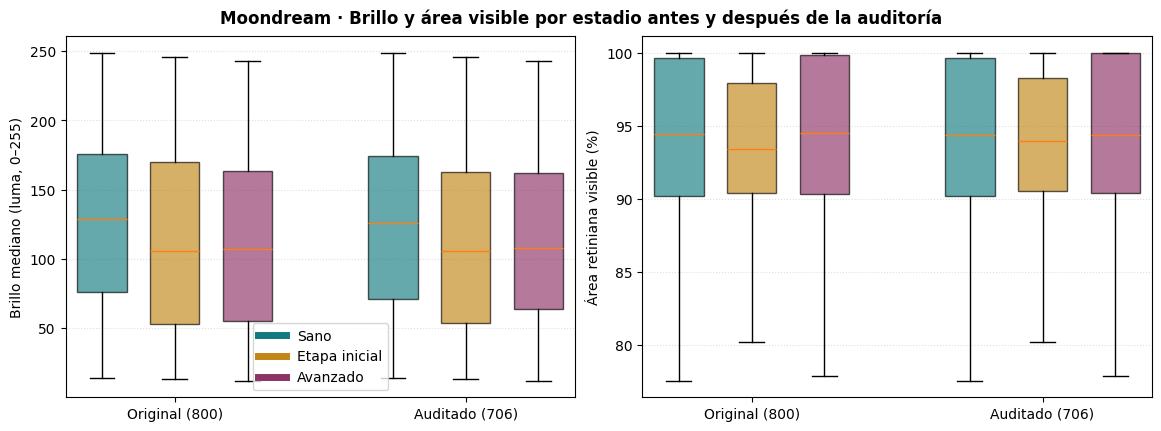

In [3]:
def esquinas(df):
    filas = []
    for p in df["id"]:
        pix = np.asarray(u.leer_rgb(ROOT, p))
        esq = [b.reshape(-1, 3).mean(0) for b in (pix[:4, :4], pix[:4, -4:], pix[-4:, :4], pix[-4:, -4:])]
        filas.append({
            "pad_negro": int(any(c.max() < 20 for c in esq)),
            "pad_gris": int(any(55 <= c.mean() <= 100 and np.ptp(c) < 8 for c in esq)),
        })
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(filas)], axis=1)

moon_hist = hrows[hrows["coleccion"] == "Moondream Staged"].rename(
    columns={"id_imagen": "id", "etiqueta": "clase", "particion": "split"}
)
moon_hist = moon_hist.merge(esquinas(moon_hist[["id"]]), on="id", how="left")
moon_clean = df_auditado[df_auditado["coleccion"] == "Moondream Staged"][["id", "clase", "split"]].merge(
    moon_hist.drop(columns=["clase", "split"]), on="id", how="left"
)

comp = pd.concat([
    moon_hist.assign(version="Original (800)"),
    moon_clean.assign(version="Auditado (706)"),
], ignore_index=True)

interes = ["brillo_mediano_yn", "negro_pct", "region_pct", "laplaciano_lado512"]
tabla_split = tabla_percentiles(comp, ["version", "split", "clase"], interes)
tabla_split.to_csv(SALIDAS / "03_moondream_por_split.csv", index=False)

resumen_moon = comp.groupby(["version", "clase"], sort=False).agg(
    n=("id", "size"),
    brillo_med=("brillo_mediano_yn", "median"),
    area_util_med=("region_pct", "median"),
    prop_pad_negro=("pad_negro", "mean"),
    prop_pad_gris=("pad_gris", "mean"),
).round(3)
display(resumen_moon)

fig, paneles = plt.subplots(1, 2, figsize=(11.5, 4.2), layout="constrained")
versiones = list(comp["version"].unique())
for ax, met, ylab in zip(paneles, ["brillo_mediano_yn", "region_pct"], ["Brillo mediano (luma, 0–255)", "Área retiniana visible (%)"]):
    for c_idx, cl in enumerate(u.ENC_3):
        for v_idx, ver in enumerate(versiones):
            vals = comp.loc[(comp["clase"] == cl) & (comp["version"] == ver), met].dropna()
            pos = v_idx * 4 + c_idx
            bp = ax.boxplot(vals, positions=[pos], widths=0.68, patch_artist=True, showfliers=False)
            bp["boxes"][0].set_facecolor(u.COLORES_CLASE[c_idx])
            bp["boxes"][0].set_alpha(0.65)
    ax.set_xticks(np.arange(len(versiones)) * 4 + 1, versiones)
    ax.set(ylabel=ylab)
    ax.grid(axis="y", ls=":", alpha=0.4)
paneles[0].legend(handles=[plt.Line2D([0], [0], color=u.COLORES_CLASE[i], lw=5, label=s) for i, s in enumerate(u.CLASES_3)])
fig.suptitle("Moondream · Brillo y área visible por estadio antes y después de la auditoría", fontweight="bold")
plt.show()

## 4. Distribuciones y varianza entre fuentes locales

Comparamos mediante **medianas y rango intercuartílico (`RIC`)** —por tratarse de variables asimétricas— las métricas medidas **exclusivamente dentro de la máscara retiniana visible** (`2.147/2.149` imágenes evaluables, excluyendo el borde negro exterior y erosionando `1 px` el contorno al calcular la nitidez a `512 px`).

**Implicación para la generalización en glaucoma:**
- **Variabilidad entre protocolos y dispositivos de captura:** `ACRIMA` y `RIM-ONE DL` son recortes papilares cerrados (`100 %` área visible, `RIC = 0,0`), mientras `EyePACS REAL` (`21,8 %`) y `EyePACS TRAIN` (`27,1 %`) conservan borde oscuro circular y distinta nitidez (`60,0` con `RIC = 62,7` en `EyePACS REAL` vs. `5,1` en `ACRIMA`).
- **Variabilidad e incentivos espurios intra-fuente:** `Moondream Staged` concentra la mayor dispersión de brillo (`RIC = 106,0`; `[65–171]`) y además muestra caída de brillo según severidad (`126 → 111 → 108`) y más relleno negro artificial en esquinas en ojos sanos (`52,7 %`) que en avanzados (`44,6 %`), mientras en `ACRIMA` el ancho nativo mediano pasa de `346 px` (`normal`) a `673 px` (`glaucoma`).
- **Puente hacia los experimentos siguientes:** estas brechas motivan evaluar cuánto resiste el aprendizaje por estadios frente al binario desde `Moondream` (Exp. `04`) y si simular cambios de escala e iluminación rescata la generalización bajo validación cruzada por origen LODO (Exp. `05`).

,Colección,n,Brillo [p25–p75] (RIC),Saturación % (RIC),Negro %,Área útil % (RIC),Nitidez 512 px (RIC)
0,ACRIMA,703,110 [92–126] (34),87.8 (11.7),0.0,100.0 (0.0),5.1 (2.9)
1,RIM-ONE DL,447,85 [63–101] (38),77.1 (14.5),0.0,100.0 (0.0),8.1 (7.5)
2,Moondream Staged,706,121 [65–171] (106),70.9 (41.5),0.0,94.1 (9.0),14.2 (20.4)
3,EyePACS REAL,200,77 [52–107] (56),61.6 (38.4),21.8,78.2 (6.4),60.0 (62.7)
4,EyePACS TRAIN,93,114 [97–123] (26),85.7 (13.3),27.1,72.8 (0.2),32.0 (11.8)


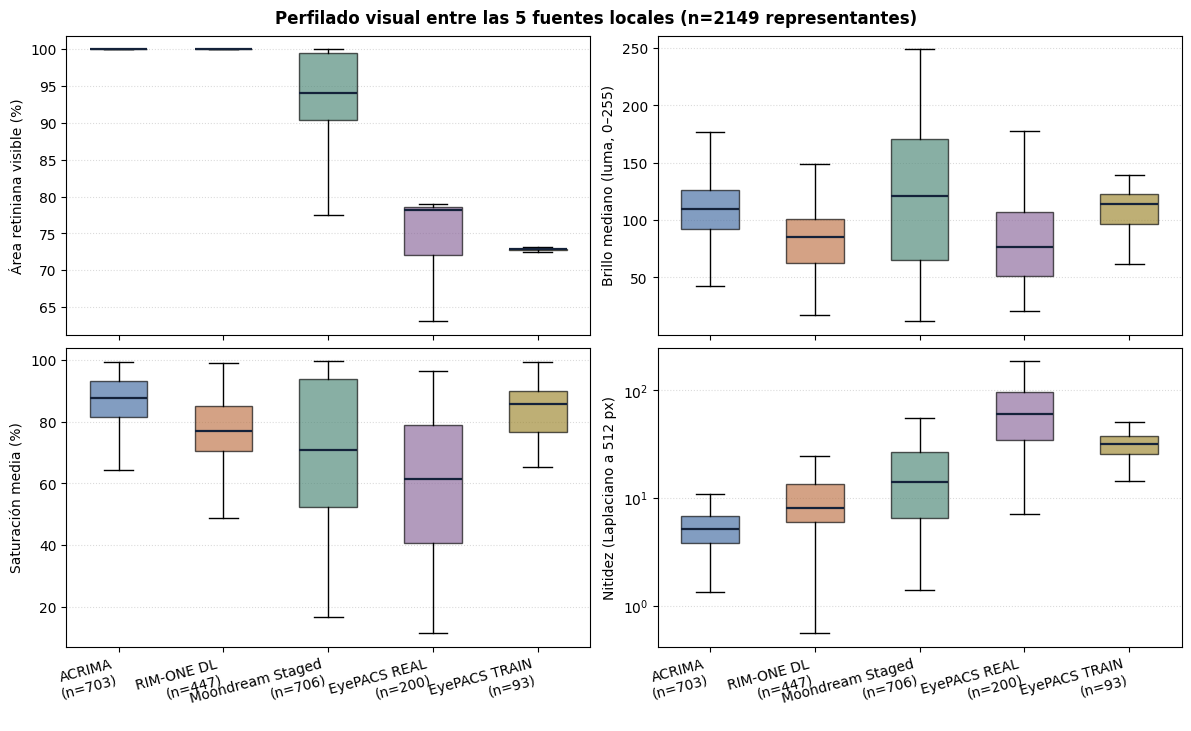

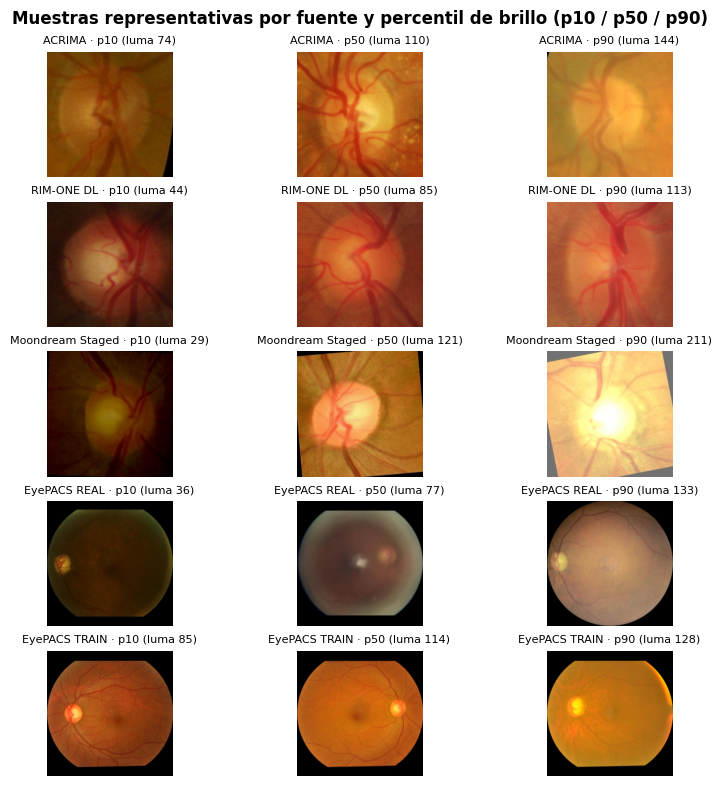

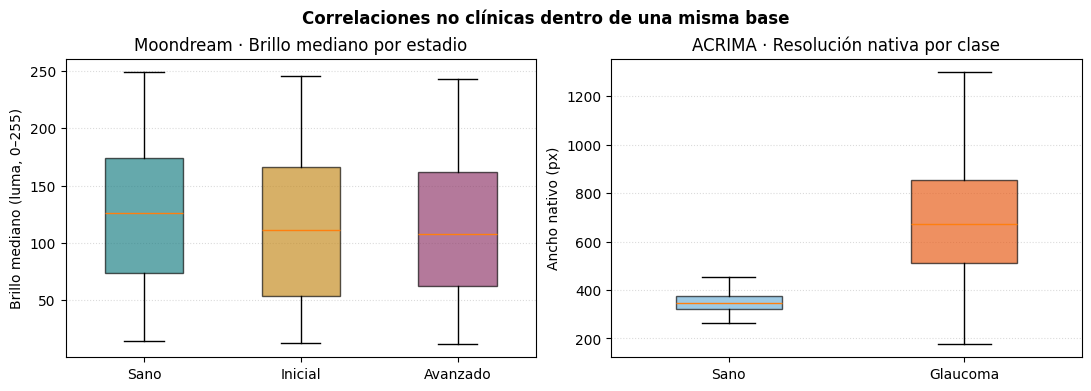

In [4]:
orden_fuentes = ["ACRIMA", "RIM-ONE DL", "Moondream Staged", "EyePACS REAL", "EyePACS TRAIN"]
fuentes = hrows[hrows["en_comparacion_fuentes"] == True].copy()
perfil_fuentes = tabla_percentiles(fuentes, ["coleccion"], FEATURES)
perfil_etiquetas = tabla_percentiles(
    hrows[hrows["coleccion"].isin(orden_fuentes)
          & hrows["en_resumen_grupo"].eq(True) & hrows["conflicto_etiqueta_grupo"].ne(True) & hrows["etiqueta"].notna()],
    ["coleccion", "esquema_etiqueta", "etiqueta"], FEATURES,
)
perfil_fuentes.to_csv(SALIDAS / "03_caracteristicas_por_fuente.csv", index=False)
perfil_etiquetas.to_csv(SALIDAS / "03_caracteristicas_por_etiqueta.csv", index=False)

# Tabla limpia alineada con Tabla 1 del informe (medianas y RIC)
tabla1 = pd.DataFrame([
    {
        "Colección": f,
        "n": int((fuentes["coleccion"] == f).sum()),
        "Brillo [p25–p75] (RIC)": (lambda r: f"{r.mediana:.0f} [{r.p25:.0f}–{r.p75:.0f}] ({r.RIC:.0f})")(
            perfil_fuentes.query("coleccion == @f and medida == 'brillo_mediano_yn'").iloc[0]
        ),
        "Saturación % (RIC)": (lambda r: f"{r.mediana:.1f} ({r.RIC:.1f})")(
            perfil_fuentes.query("coleccion == @f and medida == 'saturacion_media_pct'").iloc[0]
        ),
        "Negro %": f"{perfil_fuentes.query('coleccion == @f and medida == "negro_pct"').iloc[0].mediana:.1f}",
        "Área útil % (RIC)": (lambda r: f"{r.mediana:.1f} ({r.RIC:.1f})")(
            perfil_fuentes.query("coleccion == @f and medida == 'region_pct'").iloc[0]
        ),
        "Nitidez 512 px (RIC)": (lambda r: f"{r.mediana:.1f} ({r.RIC:.1f})")(
            perfil_fuentes.query("coleccion == @f and medida == 'laplaciano_lado512'").iloc[0]
        ),
    }
    for f in orden_fuentes
])
display(tabla1)

# 4 paneles útiles (mismas variables del artículo)
metricas_panel = [
    ("region_pct", "Área retiniana visible (%)", False),
    ("brillo_mediano_yn", "Brillo mediano (luma, 0–255)", False),
    ("saturacion_media_pct", "Saturación media (%)", False),
    ("laplaciano_lado512", "Nitidez (Laplaciano a 512 px)", True),
]
fig, axes = plt.subplots(2, 2, figsize=(11.8, 7.2), sharex=True, layout="constrained")
for ax, (met, ylab, log_y) in zip(axes.ravel(), metricas_panel):
    for idx, src in enumerate(orden_fuentes):
        vals = fuentes.loc[fuentes["coleccion"] == src, met].dropna()
        ax.boxplot(vals, positions=[idx], widths=0.55, patch_artist=True, showfliers=False,
                   boxprops={"facecolor": u.COLORES_FUENTE[idx % len(u.COLORES_FUENTE)], "alpha": 0.65},
                   medianprops={"color": "#14223a", "linewidth": 1.6})
    if log_y:
        ax.set_yscale("symlog", linthresh=1)
    ax.set_ylabel(ylab)
    ax.grid(axis="y", ls=":", alpha=0.45)
for ax in axes[1]:
    ax.set_xticks(range(len(orden_fuentes)), [f"{s}\n(n={int((fuentes['coleccion']==s).sum())})" for s in orden_fuentes], rotation=15, ha="right")
fig.suptitle(f"Perfilado visual entre las 5 fuentes locales (n={len(fuentes)} representantes)", fontweight="bold")
plt.show()

# Mosaico compacto por percentiles de brillo (p10, p50, p90) para inspección rápida de encuadre
fig, axes = plt.subplots(len(orden_fuentes), 3, figsize=(7.5, 1.55 * len(orden_fuentes)), layout="constrained")
for src, fila_ax in zip(orden_fuentes, axes):
    grp = fuentes[fuentes["coleccion"] == src].dropna(subset=["brillo_mediano_yn"]).sort_values(["brillo_mediano_yn", "id_imagen"])
    idxs = np.rint(np.array([0.1, 0.5, 0.9]) * (len(grp) - 1)).astype(int)
    for ax, (_, row), q in zip(fila_ax, grp.iloc[idxs].iterrows(), (10, 50, 90)):
        ax.axis("off")
        if (ROOT / row.id_imagen).is_file():
            ax.imshow(u.leer_rgb(ROOT, row.id_imagen).resize((224, 224)))
        ax.set_title(f"{src} · p{q} (luma {row.brillo_mediano_yn:.0f})", fontsize=8)
fig.suptitle("Muestras representativas por fuente y percentil de brillo (p10 / p50 / p90)", fontweight="bold")
plt.show()
# Asimetrías internas asociadas a etiqueta (señales espurias que dificultan la generalización)
fig, (ax_m, ax_a) = plt.subplots(1, 2, figsize=(10.8, 3.8), layout="constrained")
m_sub = fuentes[fuentes["coleccion"] == "Moondream Staged"]
m_ord = ["normal", "early", "advanced"]
bp_m = ax_m.boxplot([m_sub.loc[m_sub["etiqueta"] == c, "brillo_mediano_yn"].dropna() for c in m_ord],
                    patch_artist=True, showfliers=False, widths=0.5)
for box, col in zip(bp_m["boxes"], u.COLORES_CLASE):
    box.set_facecolor(col); box.set_alpha(0.65)
ax_m.set_xticks([1, 2, 3], ["Sano", "Inicial", "Avanzado"])
ax_m.set(title="Moondream · Brillo mediano por estadio", ylabel="Brillo mediano (luma, 0–255)")
ax_m.grid(axis="y", ls=":", alpha=0.45)

a_sub = fuentes[fuentes["coleccion"] == "ACRIMA"]
bp_a = ax_a.boxplot([a_sub.loc[a_sub["etiqueta"] == c, "ancho_px"].dropna() for c in ["normal", "glaucoma"]],
                    patch_artist=True, showfliers=False, widths=0.45)
for box, col in zip(bp_a["boxes"], ["#6baed6", "#e6550d"]):
    box.set_facecolor(col); box.set_alpha(0.65)
ax_a.set_xticks([1, 2], ["Sano", "Glaucoma"])
ax_a.set(title="ACRIMA · Resolución nativa por clase", ylabel="Ancho nativo (px)")
ax_a.grid(axis="y", ls=":", alpha=0.45)
fig.suptitle("Correlaciones no clínicas dentro de una misma base", fontweight="bold")
plt.show()

## 5. Limitaciones

- Las comparaciones entre fuentes son descriptivas y reflejan diferencias de cámara, recorte y preprocesamiento previo (ninguna colección trae metadatos EXIF de cámara por archivo ni máscaras verificadas de disco óptico).
- El área visible estima el campo retiniano útil frente a bordes negros o rellenos uniformes en esquinas.